# Living Tissue Dynamics — воспроизводимые эксперименты GNN

В работе исследуем причины накопления ошибок графовой нейронной сети (GNN) при долгосрочном прогнозировании движения клеток.

В качестве базовой модели используем GraphSAGE, обученную предсказывать смещения клеток по их предыдущим скоростям и графу соседства. Эксперименты проводим на датасете Fluo-N2DH-SIM+ из Cell Tracking Challenge.

Основная задача — понять, как меняется качество предсказаний при увеличении горизонта прогнозирования и какие факторы влияют на деградацию модели.

Для этого сравниваем режимы fixed, dynamic и oracle graph, анализируем накопление ошибок координат и изменение относительных скоростей клеток. Дополнительно проверяем влияние Gaussian noise при обучении на устойчивость свободного прогнозирования (free rollout).

Качество оцениваем с помощью ADE, FDE и статистик относительного движения клеток.

In [ ]:
%pip -q install torch-geometric numpy pandas matplotlib scipy pillow requests

import torch, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 33.3 MB/s eta 0:00:00
Device: cuda


## 1. Загрузка Fluo-N2DH-SIM+

In [ ]:

from pathlib import Path
import requests
import zipfile

url = (
    "https://data.celltrackingchallenge.net/"
    "training-datasets/Fluo-N2DH-SIM+.zip"
)

zip_path = Path("/content/Fluo-N2DH-SIM+.zip")
data_dir_sim = Path("/content/cell_data_sim")
data_dir_sim.mkdir(exist_ok=True)

if not zip_path.exists():
    response = requests.get(url, timeout=120)
    response.raise_for_status()
    zip_path.write_bytes(response.content)

with zipfile.ZipFile(zip_path) as z:
    z.extractall(data_dir_sim)

print("Датасет загружен и распакован")

for path in sorted(data_dir_sim.rglob("*")):
    if path.is_dir() and path.name == "TRA":
        print("Tracking annotations:", path)

assert (data_dir_sim / "Fluo-N2DH-SIM+" / "01_GT" / "TRA").is_dir(), "Не найдена папка аннотаций 01_GT/TRA"
assert (data_dir_sim / "Fluo-N2DH-SIM+" / "02_GT" / "TRA").is_dir(), "Не найдена папка аннотаций 02_GT/TRA"


Датасет загружен и распакован
Tracking annotations: /content/cell_data_sim/Fluo-N2DH-SIM+/01_GT/TRA
Tracking annotations: /content/cell_data_sim/Fluo-N2DH-SIM+/02_GT/TRA


## 2. Извлечение траекторий

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from PIL import Image
from scipy.ndimage import center_of_mass

root = Path("/content/cell_data_sim/Fluo-N2DH-SIM+")

all_records = []

for seq in ["01", "02"]:
    tra_dir = root / f"{seq}_GT" / "TRA"
    mask_files = sorted(tra_dir.glob("man_track*.tif"))

    print(f"Sequence {seq}: {len(mask_files)} masks")

    for mask_file in mask_files:
        frame = int(mask_file.stem.replace("man_track", ""))

        with Image.open(mask_file) as img:
            mask = np.asarray(img)

        cell_ids = np.unique(mask)
        cell_ids = cell_ids[cell_ids > 0]

        for cell_id in cell_ids:
            y, x = center_of_mass(mask == cell_id)

            all_records.append({
                "sequence": seq,
                "frame": frame,
                "cell_id": int(cell_id),
                "x": float(x),
                "y": float(y)
            })

if not all_records:
    raise RuntimeError("Tracking-маски не найдены или не прочитаны. Проверьте загрузку Fluo-N2DH-SIM+ в предыдущей ячейке.")

sim_tracks = pd.DataFrame(all_records)

print("\nВсего наблюдений:", len(sim_tracks))

for seq in ["01", "02"]:
    df = sim_tracks[sim_tracks.sequence == seq]

    cells_per_frame = df.groupby("frame").cell_id.nunique()

    print(f"\nSequence {seq}")
    print("Кадров:", df.frame.nunique())
    print("Уникальных клеток:", df.cell_id.nunique())
    print("Среднее клеток на кадре:", round(cells_per_frame.mean(), 1))
    print("Максимум клеток на кадре:", cells_per_frame.max())

display(sim_tracks.head())


Sequence 01: 65 masks
Sequence 02: 150 masks

Всего наблюдений: 5978

Sequence 01
Кадров: 65
Уникальных клеток: 95
Среднее клеток на кадре: 40.1
Максимум клеток на кадре: 47

Sequence 02
Кадров: 150
Уникальных клеток: 107
Среднее клеток на кадре: 22.5
Максимум клеток на кадре: 54


,sequence,frame,cell_id,x,y
0,01,0,1,49.086002,402.950137
1,01,0,2,457.300823,500.105350
2,01,0,3,52.721248,457.700727
3,01,0,4,506.427472,530.097245
4,01,0,5,39.964361,345.174843


## 3. Анализ графов соседства

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

radii = [20, 40, 60, 80, 100]

results = []

for seq in ["01", "02"]:
    df = sim_tracks[sim_tracks.sequence == seq]

    for frame in sorted(df.frame.unique()):
        frame_df = df[df.frame == frame]
        xy = frame_df[["x", "y"]].to_numpy()

        distances = np.linalg.norm(
            xy[:, None, :] - xy[None, :, :],
            axis=-1
        )

        for radius in radii:
            adjacency = distances < radius
            np.fill_diagonal(adjacency, False)

            n_edges = int(adjacency.sum())
            n_cells = len(xy)

            results.append({
                "sequence": seq,
                "frame": frame,
                "radius": radius,
                "n_cells": n_cells,
                "n_edges": n_edges,
                "mean_neighbors": n_edges / n_cells
            })

graph_stats = pd.DataFrame(results)

summary = (
    graph_stats
    .groupby(["sequence", "radius"])
    .agg(
        mean_cells=("n_cells", "mean"),
        mean_edges=("n_edges", "mean"),
        mean_neighbors=("mean_neighbors", "mean")
    )
    .round(2)
)

display(summary)


mean_cells  mean_edges  mean_neighbors
sequence radius                                        
01       20           40.11        0.00            0.00
         40           40.11        0.18            0.00
         60           40.11       18.34            0.44
         80           40.11       60.12            1.46
         100          40.11       97.57            2.38
02       20           22.47        0.07            0.00
         40           22.47        1.81            0.05
         60           22.47       14.65            0.51
         80           22.47       38.07            1.32
         100          22.47       55.01            1.91

## 4. Подготовка одношаговых графов

In [ ]:

import numpy as np
import torch
from torch_geometric.data import Data

RADIUS = 100.0

def make_edges(xy, radius=RADIUS):
    dist = torch.cdist(xy, xy)
    adj = dist < radius
    adj.fill_diagonal_(False)
    return adj.nonzero(as_tuple=False).T.contiguous()

def build_samples(df):
    samples = []

    frames = sorted(df.frame.unique())

    for t in frames:
        if t - 1 not in frames or t + 1 not in frames:
            continue

        prev = df[df.frame == t - 1].set_index("cell_id")
        curr = df[df.frame == t].set_index("cell_id")
        nxt = df[df.frame == t + 1].set_index("cell_id")

        ids = curr.index.to_numpy()
        xy = torch.tensor(
            curr[["x", "y"]].to_numpy(),
            dtype=torch.float32
        )

        velocity = np.zeros((len(ids), 2), dtype=np.float32)
        target = np.zeros((len(ids), 2), dtype=np.float32)
        valid = np.zeros(len(ids), dtype=bool)

        for i, cell_id in enumerate(ids):
            if cell_id in prev.index:
                velocity[i] = (
                    curr.loc[cell_id, ["x", "y"]].to_numpy(dtype=float)
                    - prev.loc[cell_id, ["x", "y"]].to_numpy(dtype=float)
                )

            if cell_id in nxt.index:
                target[i] = (
                    nxt.loc[cell_id, ["x", "y"]].to_numpy(dtype=float)
                    - curr.loc[cell_id, ["x", "y"]].to_numpy(dtype=float)
                )
                valid[i] = True

        x = torch.tensor(
            np.concatenate(
                [xy.numpy() / 512.0, velocity / 10.0],
                axis=1
            ),
            dtype=torch.float32
        )

        samples.append(
            Data(
                x=x,
                edge_index=make_edges(xy),
                y=torch.tensor(target / 10.0),
                valid=torch.tensor(valid),
                pos=xy,
                frame=int(t)
            )
        )

    return samples

train_df = sim_tracks[sim_tracks.sequence == "01"]
test_df = sim_tracks[sim_tracks.sequence == "02"]

train_samples = build_samples(train_df)
test_samples = build_samples(test_df)

print("Train samples:", len(train_samples))
print("Test samples:", len(test_samples))
print("First graph nodes:", train_samples[0].num_nodes)
print("First graph edges:", train_samples[0].num_edges)
print("Valid targets:", int(train_samples[0].valid.sum()))


Train samples: 63
Test samples: 148
First graph nodes: 30
First graph edges: 48
Valid targets: 30


## 5. Исходная GraphSAGE с координатами

In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch_geometric.nn import SAGEConv

class CellGNN(nn.Module):
    def __init__(self, hidden_dim=64):
        super().__init__()

        self.conv1 = SAGEConv(4, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, hidden_dim)

        self.mlp = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2)
        )

    def forward(self, x, edge_index):
        h = F.relu(self.conv1(x, edge_index))
        h = F.relu(self.conv2(h, edge_index))
        return self.mlp(h)

model = CellGNN(hidden_dim=64).to(device)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print(model)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters())
)


CellGNN(
  (conv1): SAGEConv(4, 64, aggr=mean)
  (conv2): SAGEConv(64, 64, aggr=mean)
  (mlp): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=2, bias=True)
  )
)
Trainable parameters: 13122


## 6. Обучение исходной модели

Epoch  10/150 | Train MSE: 0.068719
Epoch  20/150 | Train MSE: 0.066548
Epoch  30/150 | Train MSE: 0.064320
Epoch  40/150 | Train MSE: 0.061880
Epoch  50/150 | Train MSE: 0.058718
Epoch  60/150 | Train MSE: 0.055757
Epoch  70/150 | Train MSE: 0.052591
Epoch  80/150 | Train MSE: 0.049239
Epoch  90/150 | Train MSE: 0.046497
Epoch 100/150 | Train MSE: 0.043359
Epoch 110/150 | Train MSE: 0.040953
Epoch 120/150 | Train MSE: 0.038484
Epoch 130/150 | Train MSE: 0.036353
Epoch 140/150 | Train MSE: 0.033373
Epoch 150/150 | Train MSE: 0.031824


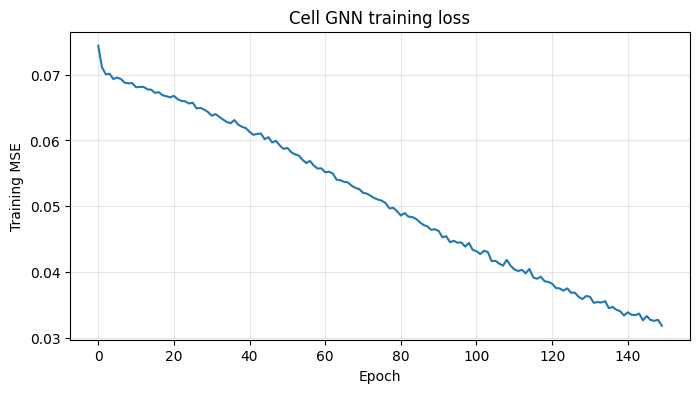

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

EPOCHS = 150
loss_history = []

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0

    np.random.shuffle(train_samples)

    for sample in train_samples:
        sample = sample.to(device)

        optimizer.zero_grad()

        pred = model(
            sample.x,
            sample.edge_index
        )

        loss = F.mse_loss(
            pred[sample.valid],
            sample.y[sample.valid]
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_samples)
    loss_history.append(avg_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch {epoch+1:3d}/{EPOCHS} | "
            f"Train MSE: {avg_loss:.6f}"
        )

plt.figure(figsize=(8, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Training MSE")
plt.title("Cell GNN training loss")
plt.grid(alpha=0.3)
plt.show()


## 7. Одношаговая оценка

,Model,Mean error (px),Median error (px),Std (px),N
1,Zero velocity,3.607008,3.529012,1.643359,3256
2,Constant velocity,4.188213,3.851386,2.402191,3256
0,GNN,4.328736,3.959904,2.419808,3256


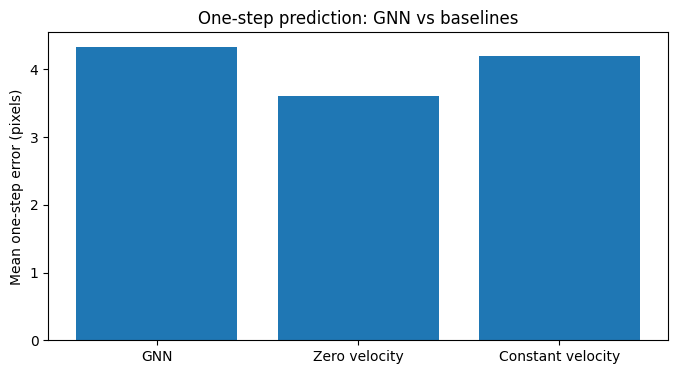

In [ ]:

import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

model.eval()

errors = {
    "GNN": [],
    "Zero velocity": [],
    "Constant velocity": []
}

with torch.no_grad():
    for sample in test_samples:
        sample = sample.to(device)

        valid = sample.valid
        if not valid.any():
            continue

        # Предсказанное смещение GNN
        pred = model(sample.x, sample.edge_index) * 10.0

        # Реальное смещение
        target = sample.y * 10.0

        # Скорость на предыдущем шаге
        velocity = sample.x[:, 2:4] * 10.0

        # Ошибка в пикселях
        for name, prediction in [
            ("GNN", pred),
            ("Zero velocity", torch.zeros_like(target)),
            ("Constant velocity", velocity)
        ]:
            error = torch.linalg.norm(
                prediction[valid] - target[valid],
                dim=1
            )

            errors[name].extend(
                error.cpu().numpy().tolist()
            )

summary = pd.DataFrame([
    {
        "Model": name,
        "Mean error (px)": np.mean(values),
        "Median error (px)": np.median(values),
        "Std (px)": np.std(values),
        "N": len(values)
    }
    for name, values in errors.items()
])

display(summary.sort_values("Mean error (px)"))

plt.figure(figsize=(8, 4))
plt.bar(
    summary["Model"],
    summary["Mean error (px)"]
)
plt.ylabel("Mean one-step error (pixels)")
plt.title("One-step prediction: GNN vs baselines")
plt.show()


## 8. Абляция рёбер

In [ ]:

import torch
import numpy as np
import pandas as pd

model.eval()

results = {
    "Original graph": [],
    "No edges": []
}

with torch.no_grad():
    for sample in test_samples:
        sample = sample.to(device)

        valid = sample.valid
        if not valid.any():
            continue

        target = sample.y * 10.0

        # Исходный граф
        pred_original = (
            model(sample.x, sample.edge_index) * 10.0
        )

        # Граф без соседей
        empty_edges = torch.empty(
            (2, 0),
            dtype=torch.long,
            device=device
        )

        pred_no_edges = (
            model(sample.x, empty_edges) * 10.0
        )

        for name, pred in [
            ("Original graph", pred_original),
            ("No edges", pred_no_edges)
        ]:
            error = torch.linalg.norm(
                pred[valid] - target[valid],
                dim=1
            )

            results[name].extend(
                error.cpu().numpy().tolist()
            )

display(pd.DataFrame([
    {
        "Graph": name,
        "Mean error (px)": np.mean(values),
        "Median error (px)": np.median(values)
    }
    for name, values in results.items()
]))


,Graph,Mean error (px),Median error (px)
0,Original graph,4.328736,3.959904
1,No edges,4.394317,4.085592


## 9. Train/Test сравнение

In [ ]:

import numpy as np
import pandas as pd
import torch

def evaluate_samples(samples, name):
    model.eval()

    errors = {
        "GNN": [],
        "Zero velocity": [],
        "Constant velocity": []
    }

    with torch.no_grad():
        for sample in samples:
            sample = sample.to(device)
            valid = sample.valid

            if not valid.any():
                continue

            target = sample.y * 10.0
            pred = model(sample.x, sample.edge_index) * 10.0
            velocity = sample.x[:, 2:4] * 10.0

            predictions = {
                "GNN": pred,
                "Zero velocity": torch.zeros_like(target),
                "Constant velocity": velocity
            }

            for method, p in predictions.items():
                error = torch.linalg.norm(
                    p[valid] - target[valid],
                    dim=1
                )

                errors[method].extend(
                    error.cpu().numpy().tolist()
                )

    return [
        {
            "Dataset": name,
            "Model": method,
            "Mean error (px)": np.mean(values),
            "Median error (px)": np.median(values)
        }
        for method, values in errors.items()
    ]

comparison = pd.DataFrame(
    evaluate_samples(train_samples, "Train") +
    evaluate_samples(test_samples, "Test")
)

display(
    comparison.pivot(
        index="Model",
        columns="Dataset",
        values="Mean error (px)"
    )
)


Dataset,Test,Train
Model,,
Constant velocity,4.188213,4.020860
GNN,4.328736,2.151144
Zero velocity,3.607008,3.599204


## 10. Распределения скоростей

,count,mean,std,min,25%,50%,75%,max
Dataset,,,,,,,,
Test,3214.0,3.606742,1.633724,0.106296,2.503202,3.535445,4.527146,17.924788
Train,2469.0,3.596058,1.607044,0.017710,2.516574,3.515816,4.546710,14.106606


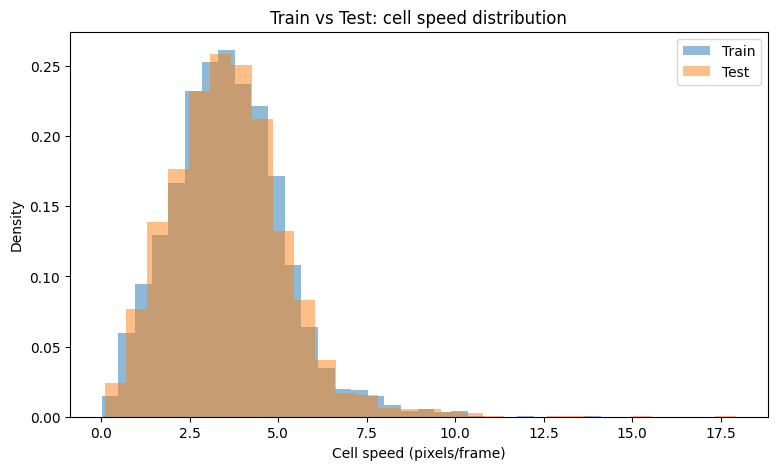

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def get_motion_stats(samples, name):
    rows = []

    for sample in samples:
        # Восстанавливаем скорость в пикселях за кадр
        velocities = (
            sample.x[:, 2:4].cpu().numpy() * 10.0
        )

        # Берём только клетки с ненулевой скоростью
        speeds = np.linalg.norm(velocities, axis=1)
        speeds = speeds[speeds > 0]

        for speed in speeds:
            rows.append({
                "Dataset": name,
                "Speed": speed
            })

    return rows

motion_df = pd.DataFrame(
    get_motion_stats(train_samples, "Train") +
    get_motion_stats(test_samples, "Test")
)

display(
    motion_df.groupby("Dataset")["Speed"]
    .describe()
)

plt.figure(figsize=(9, 5))

for name in ["Train", "Test"]:
    speeds = motion_df[
        motion_df.Dataset == name
    ].Speed

    plt.hist(
        speeds,
        bins=30,
        alpha=0.5,
        density=True,
        label=name
    )

plt.xlabel("Cell speed (pixels/frame)")
plt.ylabel("Density")
plt.title("Train vs Test: cell speed distribution")
plt.legend()
plt.show()


## 11. Velocity-only GNN

In [ ]:

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import pandas as pd
from torch_geometric.nn import SAGEConv

class VelocityGNN(nn.Module):
    def __init__(self, hidden_dim=64):
        super().__init__()

        self.conv1 = SAGEConv(2, hidden_dim)
        self.conv2 = SAGEConv(hidden_dim, hidden_dim)

        self.mlp = nn.Sequential(
            nn.Linear(hidden_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 2)
        )

    def forward(self, x, edge_index):
        h = F.relu(self.conv1(x, edge_index))
        h = F.relu(self.conv2(h, edge_index))
        return self.mlp(h)

torch.manual_seed(42)

velocity_model = VelocityGNN().to(device)

velocity_optimizer = torch.optim.Adam(
    velocity_model.parameters(),
    lr=0.001
)

# Обучаем на тех же графах
for epoch in range(150):
    velocity_model.train()
    total_loss = 0

    for sample in train_samples:
        sample = sample.to(device)

        velocity_optimizer.zero_grad()

        # Только vx, vy
        pred = velocity_model(
            sample.x[:, 2:4],
            sample.edge_index
        )

        loss = F.mse_loss(
            pred[sample.valid],
            sample.y[sample.valid]
        )

        loss.backward()
        velocity_optimizer.step()
        total_loss += loss.item()

    if (epoch + 1) % 25 == 0:
        print(
            f"Epoch {epoch+1}: "
            f"Train MSE = {total_loss / len(train_samples):.6f}"
        )

# Сравнение на тестовых данных
velocity_model.eval()
errors = []

with torch.no_grad():
    for sample in test_samples:
        sample = sample.to(device)

        pred = velocity_model(
            sample.x[:, 2:4],
            sample.edge_index
        ) * 10.0

        target = sample.y * 10.0

        error = torch.linalg.norm(
            pred[sample.valid] - target[sample.valid],
            dim=1
        )

        errors.extend(error.cpu().numpy())

print("\nVelocity-only GNN Test error:",
      np.mean(errors), "px")


Epoch 25: Train MSE = 0.066818
Epoch 50: Train MSE = 0.061501
Epoch 75: Train MSE = 0.056002
Epoch 100: Train MSE = 0.049820
Epoch 125: Train MSE = 0.044713
Epoch 150: Train MSE = 0.040089

Velocity-only GNN Test error: 4.1509037 px


## 12. Выбор тестового окна

In [ ]:

import numpy as np
import pandas as pd

# Используем только тестовую последовательность
test_tracks = (
    sim_tracks[sim_tracks.sequence == "02"]
    .copy()
)

HORIZON = 50
MIN_CELLS = 3

windows = []

frames = sorted(test_tracks.frame.unique())

for start in range(
    min(frames),
    max(frames) - HORIZON + 1
):
    end = start + HORIZON

    subset = test_tracks[
        test_tracks.frame.between(start, end)
    ]

    # Клетки, присутствующие во всех 51 кадрах
    counts = subset.groupby("cell_id").frame.nunique()

    valid_ids = counts[
        counts == HORIZON + 1
    ].index.tolist()

    windows.append({
        "start": start,
        "end": end,
        "n_cells": len(valid_ids),
        "cell_ids": valid_ids
    })

windows_df = pd.DataFrame(windows)

# Сортируем по количеству непрерывных клеток
windows_df = windows_df.sort_values(
    "n_cells",
    ascending=False
).reset_index(drop=True)

display(windows_df[
    ["start", "end", "n_cells"]
].head(15))

best_window = windows_df.iloc[0]

print("\nЛучшее окно:")
print("Start:", best_window["start"])
print("End:", best_window["end"])
print("Number of cells:", best_window["n_cells"])
print("Cell IDs:", best_window["cell_ids"])

if best_window["n_cells"] < MIN_CELLS:
    print(
        "\nWARNING: Too few cells for "
        "a meaningful graph experiment."
    )


,start,end,n_cells
0,88,138,12
1,87,137,12
2,85,135,11
3,86,136,10
4,89,139,10
5,83,133,9
6,84,134,8
7,90,140,8
8,29,79,8
9,30,80,7



Лучшее окно:
Start: 88
End: 138
Number of cells: 12
Cell IDs: [38, 40, 43, 44, 45, 46, 48, 49, 50, 51, 52, 54]


## 13. Координаты для rollout

In [ ]:

import numpy as np
import torch
import matplotlib.pyplot as plt

START = int(best_window["start"])
HORIZON = 50
CELL_IDS = list(best_window["cell_ids"])
# Начальная скорость требует предыдущего кадра.
# При отсутствии истории для некоторых ID удаляем их из диагностического окна.
previous_ids = set(test_tracks.loc[test_tracks.frame == START - 1, "cell_id"])
CELL_IDS = [cid for cid in CELL_IDS if cid in previous_ids]
if len(CELL_IDS) < 2:
    raise RuntimeError("Недостаточно непрерывных клеток с предыдущим кадром для графового rollout")
print(f"Rollout: {START}–{START+HORIZON}; клеток: {len(CELL_IDS)}")

# Для начальной скорости нужен кадр START - 1
frames_needed = np.arange(START - 1, START + HORIZON + 1)

rollout_df = sim_tracks[
    (sim_tracks.sequence == "02") &
    (sim_tracks.cell_id.isin(CELL_IDS)) &
    (sim_tracks.frame.isin(frames_needed))
].copy()

# Проверяем наличие истории для всех клеток
counts = rollout_df.groupby("cell_id").frame.nunique()
print("Кадров на клетку:")
print(counts)

# Формируем истинные координаты на кадрах START...START+HORIZON
true_positions = np.zeros(
    (HORIZON + 1, len(CELL_IDS), 2),
    dtype=np.float32
)

for i, cell_id in enumerate(CELL_IDS):
    cell_df = rollout_df[
        rollout_df.cell_id == cell_id
    ].set_index("frame")

    required = np.arange(START, START + HORIZON + 1)

    assert set(required).issubset(cell_df.index)

    true_positions[:, i] = (
        cell_df.loc[required, ["x", "y"]].to_numpy()
    )

    # Проверяем предыдущий кадр для вычисления скорости
    assert START - 1 in cell_df.index, (
        f"Нет предыдущего кадра для клетки {cell_id}"
    )

print("True positions shape:", true_positions.shape)


Rollout: 88–138; клеток: 12
Кадров на клетку:
cell_id
38    52
40    52
43    52
44    52
45    52
46    52
48    52
49    52
50    52
51    52
52    52
54    52
Name: frame, dtype: int64
True positions shape: (51, 12, 2)


## 14. Dynamic rollout

In [ ]:

import torch
import numpy as np

velocity_model.eval()

# Начальные реальные координаты
pred_positions = np.zeros_like(true_positions)
pred_positions[0] = true_positions[0]

# Начальная скорость из предыдущего кадра
prev_positions = np.zeros(
    (len(CELL_IDS), 2),
    dtype=np.float32
)

for i, cell_id in enumerate(CELL_IDS):
    cell_df = rollout_df[
        rollout_df.cell_id == cell_id
    ].set_index("frame")

    prev_positions[i] = (
        cell_df.loc[START - 1, ["x", "y"]].to_numpy()
    )

current_velocity = true_positions[0] - prev_positions

RADIUS = 100.0

with torch.no_grad():
    for t in range(HORIZON):
        pos = torch.tensor(
            pred_positions[t],
            dtype=torch.float32,
            device=device
        )

        vel = torch.tensor(
            current_velocity / 10.0,
            dtype=torch.float32,
            device=device
        )

        # Dynamic graph по предсказанным координатам
        edge_index = make_edges(pos, RADIUS)

        # Прогноз смещения
        predicted_delta = (
            velocity_model(vel, edge_index)
            .cpu().numpy() * 10.0
        )

        # Обновляем координаты и скорости
        pred_positions[t + 1] = (
            pred_positions[t] + predicted_delta
        )

        current_velocity = predicted_delta

print("Predicted positions shape:", pred_positions.shape)


Predicted positions shape: (51, 12, 2)


## 15. ADE/FDE

,Horizon,ADE (px),FDE (px)
0,1,3.920000e+00,3.920000e+00
1,5,9.652000e+00,1.874900e+01
2,10,1.408600e+02,5.339230e+02
3,20,3.088126e+03,1.888653e+04
4,50,8.464874e+07,1.315272e+09


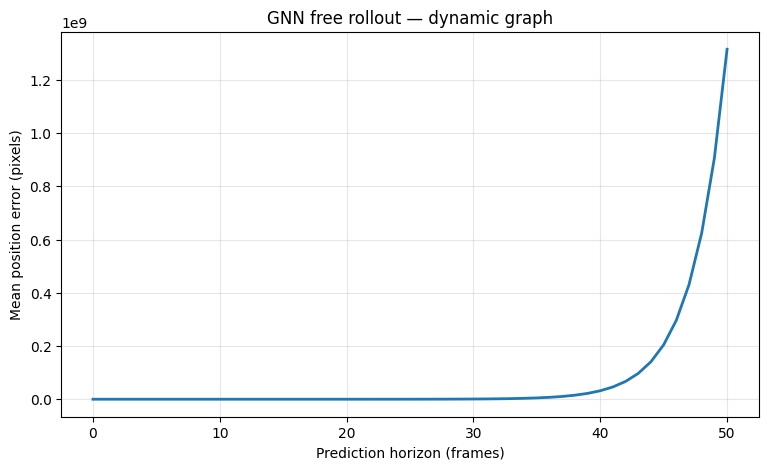

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Ошибка координат каждой клетки на каждом шаге
errors = np.linalg.norm(
    pred_positions - true_positions,
    axis=2
)

# Средняя ошибка по 12 клеткам
mean_error = errors.mean(axis=1)

results = []

for horizon in [1, 5, 10, 20, 50]:
    results.append({
        "Horizon": horizon,
        "ADE (px)": mean_error[1:horizon+1].mean(),
        "FDE (px)": mean_error[horizon]
    })

display(pd.DataFrame(results).round(3))

# График накопления ошибки
plt.figure(figsize=(9, 5))
plt.plot(
    np.arange(HORIZON + 1),
    mean_error,
    linewidth=2
)

plt.xlabel("Prediction horizon (frames)")
plt.ylabel("Mean position error (pixels)")
plt.title("GNN free rollout — dynamic graph")
plt.grid(alpha=0.3)
plt.show()


## 16. Fixed / Dynamic / Oracle

/usr/local/lib/python3.13/dist-packages/numpy/linalg/_linalg.py:2832: RuntimeWarning: overflow encountered in multiply
  s = (x.conj() * x).real


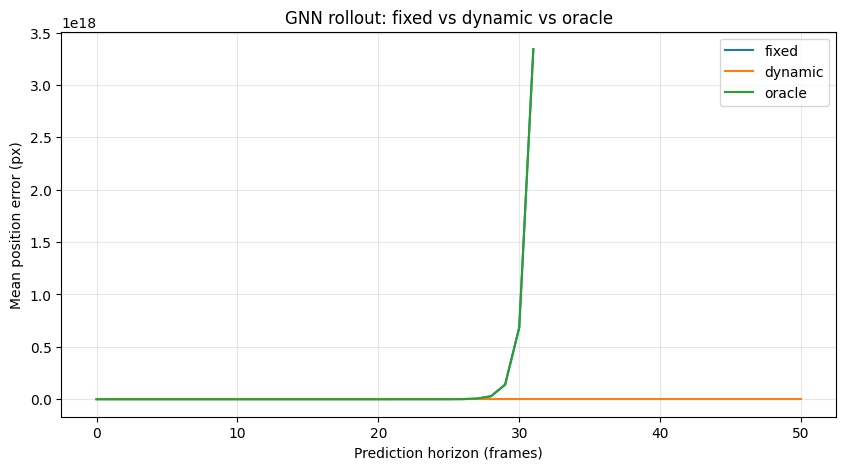

Mode,dynamic,fixed,oracle
Horizon,,,
1,3.920000e+00,3.920000e+00,3.920000e+00
5,1.874900e+01,1.874900e+01,1.855300e+01
10,5.339230e+02,1.260390e+04,1.260325e+04
20,1.888653e+04,8.760444e+10,8.760444e+10
50,1.315272e+09,inf,inf


In [ ]:

import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

RADIUS = 100.0

def run_rollout(graph_mode):
    velocity_model.eval()

    predictions = np.zeros_like(true_positions)
    predictions[0] = true_positions[0]

    current_velocity = (
        true_positions[0] - prev_positions
    ).copy()

    initial_pos = torch.tensor(
        true_positions[0],
        dtype=torch.float32,
        device=device
    )

    fixed_edges = make_edges(initial_pos, RADIUS)

    with torch.no_grad():
        for t in range(HORIZON):
            predicted_pos = torch.tensor(
                predictions[t],
                dtype=torch.float32,
                device=device
            )

            if graph_mode == "fixed":
                edges = fixed_edges

            elif graph_mode == "dynamic":
                edges = make_edges(
                    predicted_pos, RADIUS
                )

            elif graph_mode == "oracle":
                true_pos = torch.tensor(
                    true_positions[t],
                    dtype=torch.float32,
                    device=device
                )
                edges = make_edges(
                    true_pos, RADIUS
                )

            else:
                raise ValueError("Unknown graph mode")

            vel = torch.tensor(
                current_velocity / 10.0,
                dtype=torch.float32,
                device=device
            )

            delta = (
                velocity_model(vel, edges)
                .cpu().numpy() * 10.0
            )

            predictions[t + 1] = (
                predictions[t] + delta
            )

            current_velocity = delta

    return predictions


rollouts = {
    mode: run_rollout(mode)
    for mode in ["fixed", "dynamic", "oracle"]
}

results = []

plt.figure(figsize=(10, 5))

for mode, pred in rollouts.items():
    errors = np.linalg.norm(
        pred - true_positions,
        axis=2
    ).mean(axis=1)

    plt.plot(errors, label=mode)

    for horizon in [1, 5, 10, 20, 50]:
        results.append({
            "Mode": mode,
            "Horizon": horizon,
            "ADE": errors[1:horizon+1].mean(),
            "FDE": errors[horizon]
        })

plt.xlabel("Prediction horizon (frames)")
plt.ylabel("Mean position error (px)")
plt.title("GNN rollout: fixed vs dynamic vs oracle")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

results_df = pd.DataFrame(results)

display(
    results_df.pivot(
        index="Horizon",
        columns="Mode",
        values="FDE"
    ).round(3)
)


## 17. Сравнение рёбер

In [ ]:

import numpy as np
import torch
import pandas as pd

def edge_set(positions, radius=100.0):
    xy = torch.tensor(
        positions,
        dtype=torch.float32,
        device=device
    )

    edges = make_edges(xy, radius)

    return set(
        map(tuple, edges.T.cpu().tolist())
    )

initial_edges = edge_set(true_positions[0])

records = []

for t in range(HORIZON + 1):
    fixed = initial_edges
    dynamic = edge_set(rollouts["dynamic"][t])
    oracle = edge_set(true_positions[t])

    def jaccard(a, b):
        if not a and not b:
            return 1.0
        return len(a & b) / len(a | b)

    records.append({
        "Step": t,
        "Fixed edges": len(fixed),
        "Dynamic edges": len(dynamic),
        "Oracle edges": len(oracle),
        "Fixed vs Dynamic": jaccard(fixed, dynamic),
        "Dynamic vs Oracle": jaccard(dynamic, oracle)
    })

edge_comparison = pd.DataFrame(records)

display(
    edge_comparison[
        edge_comparison.Step.isin([0, 1, 5, 10, 20, 50])
    ].round(3)
)

print(
    "Steps where Fixed != Dynamic:",
    sum(
        edge_comparison["Fixed vs Dynamic"] < 1
    )
)


,Step,Fixed edges,Dynamic edges,Oracle edges,Fixed vs Dynamic,Dynamic vs Oracle
0,0,20,20,20,1.0,1.000
1,1,20,20,20,1.0,1.000
5,5,20,20,18,1.0,0.900
10,10,20,16,16,0.8,0.600
20,20,20,16,18,0.8,0.545
50,50,20,4,16,0.2,0.250


Steps where Fixed != Dynamic: 44


## 18. Изменение попарных расстояний

In [ ]:

import numpy as np
import pandas as pd

def pairwise_distances(xy):
    return np.linalg.norm(
        xy[:, None, :] - xy[None, :, :],
        axis=-1
    )

initial_dist = pairwise_distances(true_positions[0])

records = []

for t in [0, 1, 5, 10, 20, 50]:
    pred_dist = pairwise_distances(rollouts["dynamic"][t])

    true_dist = pairwise_distances(
        true_positions[t]
    )

    # Только уникальные пары клеток
    upper = np.triu_indices(
        len(CELL_IDS), k=1
    )

    pred_change = np.abs(
        pred_dist[upper] - initial_dist[upper]
    )

    true_change = np.abs(
        true_dist[upper] - initial_dist[upper]
    )

    records.append({
        "Step": t,
        "Mean predicted distance change": pred_change.mean(),
        "Mean true distance change": true_change.mean(),
        "Max predicted distance change": pred_change.max(),
        "Max true distance change": true_change.max()
    })

display(pd.DataFrame(records).round(2))


,Step,Mean predicted distance change,Mean true distance change,Max predicted distance change,Max true distance change
0,0,0.000000e+00,0.000000,0.000000e+00,0.000000
1,1,2.590000e+00,3.760000,7.690000e+00,10.070000
2,5,1.110000e+01,7.670000,3.842000e+01,19.870001
3,10,6.727100e+02,10.700000,2.686230e+03,30.059999
4,20,3.408776e+04,17.219999,1.313069e+05,51.709999
5,50,2.400248e+09,28.250000,9.262621e+09,107.760002


## 19. Относительные скорости

,Horizon,Real relative speed,Predicted relative speed
0,1,5.923,3.944000e+00
1,5,4.598,5.228000e+00
2,10,4.441,9.005600e+01
3,20,4.687,1.718295e+03
4,50,4.780,4.800497e+07


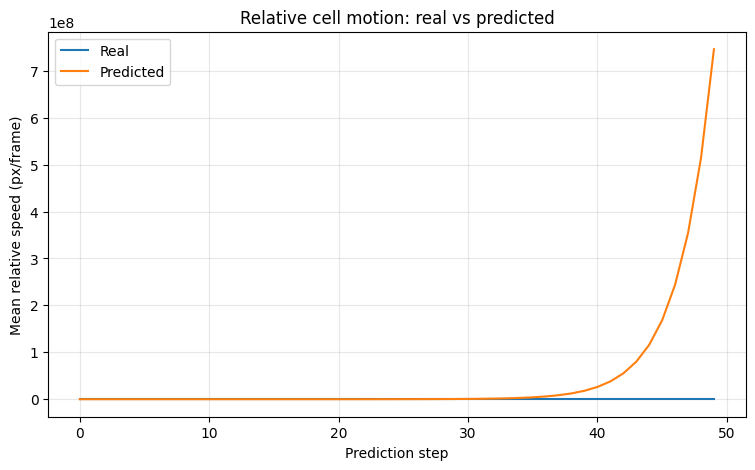

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def relative_velocity_stats(positions):
    # Скорости клеток
    velocities = np.diff(positions, axis=0)

    # Разность скоростей между всеми парами клеток
    relative = (
        velocities[:, :, None, :] -
        velocities[:, None, :, :]
    )

    relative_speed = np.linalg.norm(
        relative, axis=-1
    )

    # Уникальные пары клеток
    upper = np.triu_indices(
        positions.shape[1], k=1
    )

    return relative_speed[:, upper[0], upper[1]].mean(axis=1)

real_rel_speed = relative_velocity_stats(true_positions)
pred_rel_speed = relative_velocity_stats(rollouts["dynamic"])

results = []

for horizon in [1, 5, 10, 20, 50]:
    results.append({
        "Horizon": horizon,
        "Real relative speed": real_rel_speed[:horizon].mean(),
        "Predicted relative speed": pred_rel_speed[:horizon].mean()
    })

display(pd.DataFrame(results).round(3))

plt.figure(figsize=(9, 5))
plt.plot(real_rel_speed, label="Real")
plt.plot(pred_rel_speed, label="Predicted")

plt.xlabel("Prediction step")
plt.ylabel("Mean relative speed (px/frame)")
plt.title("Relative cell motion: real vs predicted")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 20. Teacher forcing

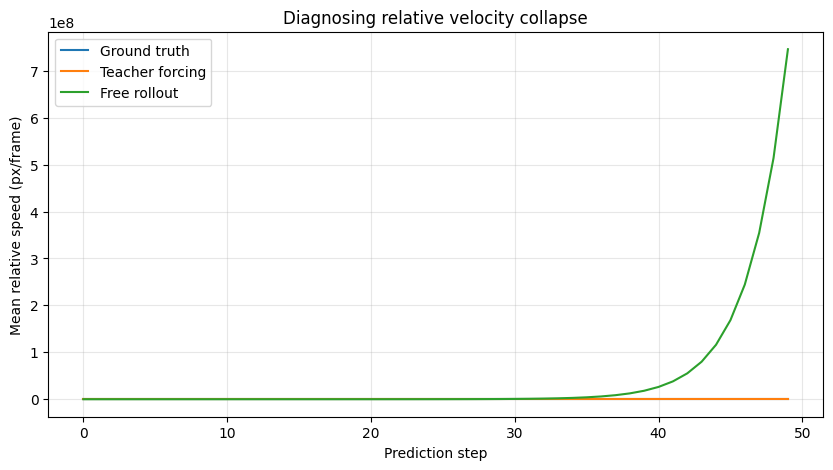

,Mode,Mean relative speed
0,Ground truth,4.780000e+00
1,Teacher forcing,4.105000e+00
2,Free rollout,4.800497e+07


In [ ]:

import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

velocity_model.eval()

# Реальные скорости на каждом шаге
true_velocities = np.diff(true_positions, axis=0)

teacher_pred_velocities = []

with torch.no_grad():
    for t in range(HORIZON):
        if t == 0:
            input_velocity = (
                true_positions[0] - prev_positions
            )
        else:
            input_velocity = true_velocities[t - 1]

        # Граф по реальным координатам текущего кадра
        pos = torch.tensor(
            true_positions[t],
            dtype=torch.float32,
            device=device
        )

        edges = make_edges(pos, RADIUS)

        vel = torch.tensor(
            input_velocity / 10.0,
            dtype=torch.float32,
            device=device
        )

        pred_delta = (
            velocity_model(vel, edges)
            .cpu().numpy() * 10.0
        )

        teacher_pred_velocities.append(pred_delta)

teacher_pred_velocities = np.array(
    teacher_pred_velocities
)

# Скорости свободного прогноза
free_pred_velocities = np.diff(
    rollouts["dynamic"], axis=0
)

def mean_relative_speed(velocities):
    relative = (
        velocities[:, :, None, :] -
        velocities[:, None, :, :]
    )
    speed = np.linalg.norm(relative, axis=-1)
    upper = np.triu_indices(
        velocities.shape[1], k=1
    )
    return speed[:, upper[0], upper[1]].mean(axis=1)

real_curve = mean_relative_speed(true_velocities)
teacher_curve = mean_relative_speed(teacher_pred_velocities)
free_curve = mean_relative_speed(free_pred_velocities)

plt.figure(figsize=(10, 5))
plt.plot(real_curve, label="Ground truth")
plt.plot(teacher_curve, label="Teacher forcing")
plt.plot(free_curve, label="Free rollout")

plt.xlabel("Prediction step")
plt.ylabel("Mean relative speed (px/frame)")
plt.title("Diagnosing relative velocity collapse")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

summary = pd.DataFrame({
    "Mode": ["Ground truth", "Teacher forcing", "Free rollout"],
    "Mean relative speed": [
        real_curve.mean(),
        teacher_curve.mean(),
        free_curve.mean()
    ]
})

display(summary.round(3))


## 21. Контролируемые подстановки

In [ ]:

import numpy as np
import torch
import pandas as pd

velocity_model.eval()

true_velocities = np.diff(true_positions, axis=0)
free_velocities = np.diff(rollouts["dynamic"], axis=0)

conditions = {
    "Real velocity + Real graph": ("real", "real"),
    "Pred velocity + Real graph": ("pred", "real"),
    "Real velocity + Pred graph": ("real", "pred"),
    "Pred velocity + Pred graph": ("pred", "pred"),
}

records = []

with torch.no_grad():
    for name, (vel_source, graph_source) in conditions.items():
        predicted_deltas = []

        for t in range(HORIZON):
            if vel_source == "real":
                if t == 0:
                    input_vel = true_positions[0] - prev_positions
                else:
                    input_vel = true_velocities[t - 1]
            else:
                if t == 0:
                    input_vel = true_positions[0] - prev_positions
                else:
                    input_vel = free_velocities[t - 1]

            if graph_source == "real":
                graph_pos = true_positions[t]
            else:
                graph_pos = rollouts["dynamic"][t]

            pos_tensor = torch.tensor(
                graph_pos,
                dtype=torch.float32,
                device=device
            )

            vel_tensor = torch.tensor(
                input_vel / 10.0,
                dtype=torch.float32,
                device=device
            )

            edges = make_edges(pos_tensor, RADIUS)

            delta = (
                velocity_model(vel_tensor, edges)
                .cpu().numpy() * 10.0
            )

            predicted_deltas.append(delta)

        predicted_deltas = np.array(predicted_deltas)

        relative_speed = mean_relative_speed(predicted_deltas)

        records.append({
            "Condition": name,
            "Mean relative speed": relative_speed.mean(),
            "One-step delta MAE (px)": np.linalg.norm(
                predicted_deltas - true_velocities,
                axis=2
            ).mean()
        })

display(pd.DataFrame(records).round(3))


,Condition,Mean relative speed,One-step delta MAE (px)
0,Real velocity + Real graph,4.105000e+00,4.262000e+00
1,Pred velocity + Real graph,1.357495e+08,8.438066e+07
2,Real velocity + Pred graph,3.639000e+00,4.020000e+00
3,Pred velocity + Pred graph,4.800497e+07,2.630545e+07


## 22. Сохранение baseline

In [ ]:

import torch
from pathlib import Path

save_dir = Path("/content/gnn_experiments")
save_dir.mkdir(exist_ok=True)

torch.save({
    "model_state_dict": velocity_model.state_dict(),
    "model_name": "VelocityGNN",
    "hidden_dim": 64,
    "radius": RADIUS,
    "train_sequence": "01",
    "test_sequence": "02",
    "epochs": 150
}, save_dir / "velocity_gnn_baseline.pt")

print("Baseline saved:", save_dir / "velocity_gnn_baseline.pt")
print("Файл хранится временно в Colab; личный Google Drive не нужен.")


Baseline saved: /content/gnn_experiments/velocity_gnn_baseline.pt
Файл хранится временно в Colab; личный Google Drive не нужен.


## 24. Обучение Gaussian GNN

In [ ]:

import torch
import torch.nn.functional as F
import numpy as np

torch.manual_seed(42)
np.random.seed(42)

# Новая модель с той же архитектурой
gaussian_model = VelocityGNN(hidden_dim=64).to(device)

gaussian_optimizer = torch.optim.Adam(
    gaussian_model.parameters(),
    lr=0.001
)

EPOCHS = 150
NOISE_STD = 0.1  # В нормализованных единицах скорости

for epoch in range(EPOCHS):
    gaussian_model.train()
    total_loss = 0.0

    for sample in train_samples:
        sample = sample.to(device)

        gaussian_optimizer.zero_grad()

        # Добавляем шум только к входным скоростям
        velocity = sample.x[:, 2:4]

        noisy_velocity = velocity + (
            torch.randn_like(velocity) * NOISE_STD
        )

        pred = gaussian_model(
            noisy_velocity,
            sample.edge_index
        )

        # Целевые смещения оставляем исходными
        loss = F.mse_loss(
            pred[sample.valid],
            sample.y[sample.valid]
        )

        loss.backward()
        gaussian_optimizer.step()

        total_loss += loss.item()

    if (epoch + 1) % 25 == 0:
        print(
            f"Epoch {epoch+1}: "
            f"Train MSE = {total_loss / len(train_samples):.6f}"
        )

print("Gaussian noise training complete!")


Epoch 25: Train MSE = 0.069381
Epoch 50: Train MSE = 0.068570
Epoch 75: Train MSE = 0.067382
Epoch 100: Train MSE = 0.066680
Epoch 125: Train MSE = 0.065178
Epoch 150: Train MSE = 0.064834
Gaussian noise training complete!


## 25. Сравнение rollout

ADE                          FDE              
Model   Gaussian noise      No noise Gaussian noise      No noise
Horizon                                                          
1             3.929000  3.920000e+00       3.929000  3.920000e+00
5             6.363000  9.652000e+00       8.728000  1.874900e+01
10            9.598000  1.408600e+02      15.420000  5.339230e+02
20           15.435000  3.088126e+03      24.955000  1.888653e+04
50           32.540001  8.464874e+07      59.019001  1.315272e+09

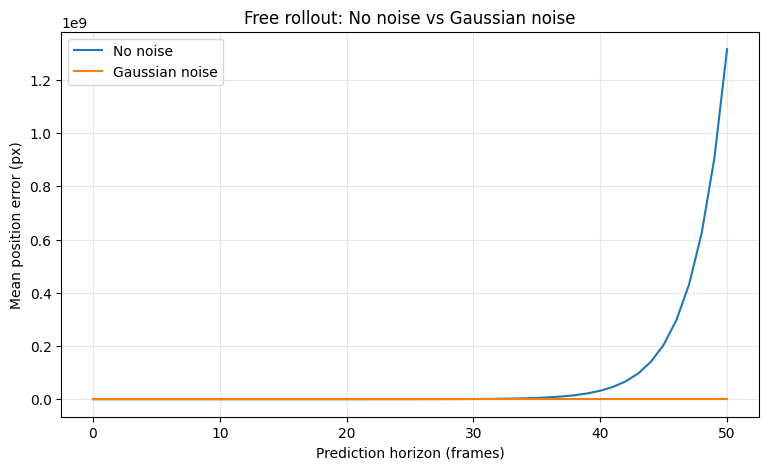

In [ ]:

import numpy as np
import torch
import pandas as pd
import matplotlib.pyplot as plt

def rollout_model(net, horizon=50):
    net.eval()

    predictions = np.zeros_like(true_positions)
    predictions[0] = true_positions[0]

    current_velocity = (
        true_positions[0] - prev_positions
    ).copy()

    with torch.no_grad():
        for t in range(horizon):
            pos = torch.tensor(
                predictions[t],
                dtype=torch.float32,
                device=device
            )

            vel = torch.tensor(
                current_velocity / 10.0,
                dtype=torch.float32,
                device=device
            )

            # Dynamic graph
            edges = make_edges(pos, RADIUS)

            delta = (
                net(vel, edges)
                .cpu().numpy() * 10.0
            )

            predictions[t + 1] = predictions[t] + delta
            current_velocity = delta

    return predictions


baseline_pred = rollout_model(velocity_model)
gaussian_pred = rollout_model(gaussian_model)

def evaluate_rollout(pred, name):
    errors = np.linalg.norm(
        pred - true_positions,
        axis=2
    ).mean(axis=1)

    rows = []

    for horizon in [1, 5, 10, 20, 50]:
        rows.append({
            "Model": name,
            "Horizon": horizon,
            "ADE": errors[1:horizon+1].mean(),
            "FDE": errors[horizon]
        })

    return rows, errors


baseline_rows, baseline_errors = evaluate_rollout(
    baseline_pred, "No noise"
)

gaussian_rows, gaussian_errors = evaluate_rollout(
    gaussian_pred, "Gaussian noise"
)

comparison = pd.DataFrame(
    baseline_rows + gaussian_rows
)

display(
    comparison.pivot(
        index="Horizon",
        columns="Model",
        values=["ADE", "FDE"]
    ).round(3)
)

plt.figure(figsize=(9, 5))
plt.plot(baseline_errors, label="No noise")
plt.plot(gaussian_errors, label="Gaussian noise")

plt.xlabel("Prediction horizon (frames)")
plt.ylabel("Mean position error (px)")
plt.title("Free rollout: No noise vs Gaussian noise")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## 26. Диагностика Gaussian noise

,Model,Mean relative speed,Final-step relative speed
0,Ground truth,4.780000e+00,4.513000e+00
1,No noise,4.800497e+07,7.458160e+08
2,Gaussian noise,2.520000e-01,1.850000e-01


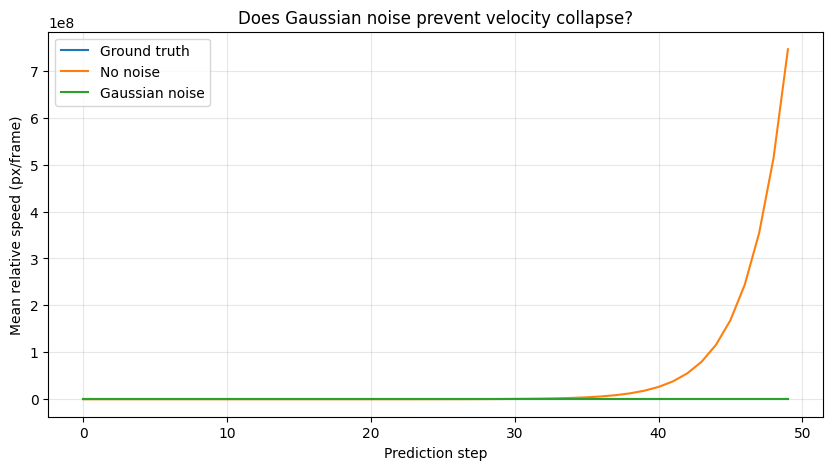

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Скорости из предсказанных траекторий
baseline_vel = np.diff(baseline_pred, axis=0)
gaussian_vel = np.diff(gaussian_pred, axis=0)
real_vel = np.diff(true_positions, axis=0)

# Используем функцию из предыдущего эксперимента
baseline_rel = mean_relative_speed(baseline_vel)
gaussian_rel = mean_relative_speed(gaussian_vel)
real_rel = mean_relative_speed(real_vel)

summary = pd.DataFrame({
    "Model": [
        "Ground truth",
        "No noise",
        "Gaussian noise"
    ],
    "Mean relative speed": [
        real_rel.mean(),
        baseline_rel.mean(),
        gaussian_rel.mean()
    ],
    "Final-step relative speed": [
        real_rel[-1],
        baseline_rel[-1],
        gaussian_rel[-1]
    ]
})

display(summary.round(3))

plt.figure(figsize=(10, 5))
plt.plot(real_rel, label="Ground truth")
plt.plot(baseline_rel, label="No noise")
plt.plot(gaussian_rel, label="Gaussian noise")

plt.xlabel("Prediction step")
plt.ylabel("Mean relative speed (px/frame)")
plt.title("Does Gaussian noise prevent velocity collapse?")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


## Ограничения и выводы

- Выборка для 50-шагового rollout — одно окно и 12 клеток; граф не содержит всех клеток кадра.
- Радиус 100 px — технический выбор, без физической калибровки.
- Gaussian noise сравнивался в одном запуске; нужны несколько seeds и уровней шума.
- Следующие проверки: MSD, VACF, neighborhood error, empirical residual noise и tracking-like noise.

In [ ]:
from pathlib import Path
import torch

output_dir = Path('/content/gnn_experiments')
output_dir.mkdir(parents=True, exist_ok=True)

torch.save({
    'model_state_dict': velocity_model.state_dict(),
    'model_name': 'VelocityGNN',
    'hidden_dim': 64,
    'radius': RADIUS,
    'train_sequence': '01',
    'test_sequence': '02',
    'epochs': 150,
    'noise_std': 0.0,
}, output_dir / 'velocity_gnn_baseline.pt')

torch.save({
    'model_state_dict': gaussian_model.state_dict(),
    'model_name': 'VelocityGNN',
    'hidden_dim': 64,
    'radius': RADIUS,
    'train_sequence': '01',
    'test_sequence': '02',
    'epochs': 150,
    'noise_std': NOISE_STD,
}, output_dir / 'gaussian_gnn.pt')

print('Saved model weights:')
for path in sorted(output_dir.glob('*.pt')):
    print(f' - {path} ({path.stat().st_size / 1024:.1f} KB)')


Saved model weights:
 - /content/gnn_experiments/gaussian_gnn.pt (54.8 KB)
 - /content/gnn_experiments/velocity_gnn_baseline.pt (55.0 KB)


## 27. Расширенная диагностика noise injection

Контролируемое сравнение: no noise, Gaussian noise (σ=0.03 и 0.10 в нормализованных единицах), empirical residual noise и tracking-like noise. Для каждого варианта — три seed. Все модели обучаются только на Sequence 01. Это дополнительные предварительные эксперименты, не подбор параметров на тестовой выборке.

In [ ]:
import random, numpy as np, pandas as pd, torch
import torch.nn.functional as F

SEEDS = [11, 22, 33]
NOISE_EPOCHS = 75
CONFIGS = {
    "No noise": ("none", 0.),
    "Gaussian 0.03": ("gaussian", 0.03),
    "Gaussian 0.10": ("gaussian", 0.10),
    "Empirical residual": ("residual", 1.),
    "Tracking-like": ("tracking", 1.)
}

def set_all_seeds(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

# Residual noise калибруем только на обучающей Sequence 01:
# отдельная модель обучается на ранних 75% кадров,
# остатки собираются на оставшихся 25%.
split = int(len(train_samples) * 0.75)
set_all_seeds(2026)
calib = VelocityGNN(hidden_dim=64).to(device)
opt = torch.optim.Adam(calib.parameters(), lr=0.001)
for epoch in range(75):
    calib.train()
    for sample in train_samples[:split]:
        s = sample.to(device)
        if not bool(s.valid.any()):
            continue
        opt.zero_grad()
        pred = calib(s.x[:, 2:4], s.edge_index)
        loss = F.mse_loss(pred[s.valid], s.y[s.valid])
        loss.backward()
        opt.step()

calib.eval()
residuals = []
with torch.no_grad():
    for sample in train_samples[split:]:
        s = sample.to(device)
        if bool(s.valid.any()):
            pred = calib(s.x[:, 2:4], s.edge_index)
            residuals.append((pred[s.valid] - s.y[s.valid]).cpu())
residual_bank = torch.cat(residuals)
residual_bank -= residual_bank.mean(dim=0, keepdim=True)
print("Calibration residuals:", len(residual_bank))

def noisy_input(vel, kind, scale):
    if kind == "none":
        return vel
    if kind == "gaussian":
        return vel + torch.randn_like(vel) * scale
    if kind == "residual":
        indices = torch.randint(len(residual_bank), (len(vel),))
        return vel + scale * residual_bank[indices].to(vel.device)
    if kind == "tracking":
        # Разность ошибок локализации на двух кадрах.
        # σ=0.7 px; редкие (2%) ошибки 3 px.
        eps_now = torch.randn_like(vel) * 0.7
        eps_prev = torch.randn_like(vel) * 0.7
        outliers = (torch.rand((len(vel), 1), device=vel.device) < 0.02)
        noise = (eps_now - eps_prev + outliers * torch.randn_like(vel) * 3.0) / 10.
        return vel + scale * noise
    raise ValueError(kind)

def train_noise_variant(kind, scale, seed):
    set_all_seeds(seed)
    net = VelocityGNN(hidden_dim=64).to(device)
    optimizer = torch.optim.Adam(net.parameters(), lr=0.001)
    rng = np.random.default_rng(seed)
    for epoch in range(NOISE_EPOCHS):
        net.train()
        for index in rng.permutation(len(train_samples)):
            s = train_samples[int(index)].to(device)
            if not bool(s.valid.any()):
                continue
            optimizer.zero_grad()
            inp = noisy_input(s.x[:, 2:4], kind, scale)
            pred = net(inp, s.edge_index)
            loss = F.mse_loss(pred[s.valid], s.y[s.valid])
            loss.backward()
            optimizer.step()
    return net

trained_variants = {}
for seed in SEEDS:
    for label, (kind, scale) in CONFIGS.items():
        trained_variants[(label, seed)] = train_noise_variant(kind, scale, seed)
        print("Trained:", label, "seed", seed)

Calibration residuals: 588
Trained: No noise seed 11
Trained: Gaussian 0.03 seed 11
Trained: Gaussian 0.10 seed 11
Trained: Empirical residual seed 11
Trained: Tracking-like seed 11
Trained: No noise seed 22
Trained: Gaussian 0.03 seed 22
Trained: Gaussian 0.10 seed 22
Trained: Empirical residual seed 22
Trained: Tracking-like seed 22
Trained: No noise seed 33
Trained: Gaussian 0.03 seed 33
Trained: Gaussian 0.10 seed 33
Trained: Empirical residual seed 33
Trained: Tracking-like seed 33


## 28. Проверка на нескольких тестовых окнах и дополнительные метрики

Выбираем три разнесённых 50-шаговых окна Sequence 02, если в них есть хотя бы три клетки с непрерывной историей. Окна одной последовательности могут перекрываться и **не являются независимыми биологическими повторениями**. Сравниваем ADE/FDE, ошибку кривой MSD, ошибку velocity autocorrelation (VACF) и ошибку соседства (`1 − Jaccard`).

In [ ]:
TEST_H = 50
test_tracks02 = sim_tracks[sim_tracks.sequence == "02"].copy()
frame_max = int(test_tracks02.frame.max())
candidate_windows = []
for start in range(int(test_tracks02.frame.min()) + 1, frame_max - TEST_H + 1):
    subset = test_tracks02[test_tracks02.frame.between(start-1, start+TEST_H)]
    counts = subset.groupby("cell_id").frame.nunique()
    ids = sorted(counts[counts == TEST_H + 2].index.tolist())
    if len(ids) >= 3:
        candidate_windows.append((start, ids))
if not candidate_windows:
    raise ValueError("Не найдено окон с 3 непрерывными траекториями")

# Выбираем три разнесённых окна, не максимизируя метрики на Test.
targets = np.linspace(candidate_windows[0][0], candidate_windows[-1][0], 3)
chosen = []
for target in targets:
    available = [(s, ids) for s, ids in candidate_windows if s not in [w[0] for w in chosen]]
    if available:
        chosen.append(min(available, key=lambda w: abs(w[0] - target)))
print("Test windows:", [(s, len(ids)) for s, ids in chosen])

def get_window(start, ids):
    frame_range = np.arange(start-1, start+TEST_H+1)
    pos = np.empty((len(frame_range), len(ids), 2), dtype=np.float32)
    for i, cid in enumerate(ids):
        part = test_tracks02[test_tracks02.cell_id == cid].set_index("frame")
        pos[:, i] = part.loc[frame_range, ["x", "y"]].to_numpy(dtype=np.float32)
    return pos[1:], pos[0]

def predict_rollout(net, truth, previous, graph_mode="dynamic"):
    predicted = np.zeros_like(truth)
    predicted[0] = truth[0]
    velocity = truth[0] - previous
    fixed = make_edges(torch.tensor(truth[0], dtype=torch.float32, device=device), RADIUS)
    net.eval()
    with torch.no_grad():
        for t in range(len(truth)-1):
            graph_positions = truth[t] if graph_mode == "oracle" else predicted[t]
            edges = fixed if graph_mode == "fixed" else make_edges(
                torch.tensor(graph_positions, dtype=torch.float32, device=device), RADIUS)
            inp = torch.tensor(velocity / 10., dtype=torch.float32, device=device)
            delta = net(inp, edges).cpu().numpy() * 10.
            predicted[t+1] = predicted[t] + delta
            velocity = delta
    return predicted

def neighbors(xy):
    d = np.linalg.norm(xy[:, None] - xy[None, :], axis=-1)
    upper = np.triu_indices(len(xy), 1)
    return set(zip(upper[0][d[upper] < RADIUS].tolist(),
                   upper[1][d[upper] < RADIUS].tolist()))

def score_rollout(pred, truth, previous):
    err = np.linalg.norm(pred-truth, axis=2).mean(axis=1)
    msd_pred = np.sum((pred-pred[0])**2, axis=2).mean(axis=1)
    msd_true = np.sum((truth-truth[0])**2, axis=2).mean(axis=1)
    v0 = truth[0] - previous
    vp, vt = np.diff(pred, axis=0), np.diff(truth, axis=0)
    vacf_pred = (vp*v0[None]).sum(axis=2).mean(axis=1)
    vacf_true = (vt*v0[None]).sum(axis=2).mean(axis=1)
    ne = []
    for t in range(1, len(truth)):
        a, b = neighbors(pred[t]), neighbors(truth[t])
        ne.append(0. if not (a or b) else 1-len(a&b)/len(a|b))
    return {
        "ADE@50": float(err[1:].mean()),
        "FDE@50": float(err[-1]),
        "MSD MAE": float(np.abs(msd_pred[1:]-msd_true[1:]).mean()),
        "VACF MAE": float(np.abs(vacf_pred-vacf_true).mean()),
        "Neighborhood error": float(np.mean(ne))
    }

rows = []
for start, ids in chosen:
    truth, previous = get_window(start, ids)
    for (name, seed), net in trained_variants.items():
        pred = predict_rollout(net, truth, previous)
        rows.append({"Model": name, "Seed": seed, "Window": start,
                     "Cells": len(ids), **score_rollout(pred, truth, previous)})
extended_results = pd.DataFrame(rows)
display(extended_results.groupby("Model")[
    ["ADE@50", "FDE@50", "MSD MAE", "VACF MAE", "Neighborhood error"]
].agg(["mean", "std"]).round(3))
display(extended_results.round(3))

Test windows: [(26, 4), (75, 4), (99, 3)]


ADE@50         FDE@50           MSD MAE          VACF MAE  \
                      mean    std    mean     std      mean      std     mean   
Model                                                                           
Empirical residual  17.445  2.309  28.808   3.775   237.724   78.177    4.984   
Gaussian 0.03       41.779  5.632  77.992  11.688  1906.240  641.205    5.797   
Gaussian 0.10       30.465  4.746  55.439   9.852   823.460  341.201    5.281   
No noise            41.860  5.849  78.427  12.136  2019.214  534.787    5.717   
Tracking-like       27.725  7.748  50.328  15.784   733.343  465.358    5.236   

                          Neighborhood error         
                      std               mean    std  
Model                                                
Empirical residual  0.887              0.076  0.085  
Gaussian 0.03       0.727              0.037  0.018  
Gaussian 0.10       0.698              0.057  0.065  
No noise            0.788              0.038  0.019  
Tracking-like       0.750              0.038  0.018

,Model,Seed,Window,Cells,ADE@50,FDE@50,MSD MAE,VACF MAE,Neighborhood error
0,No noise,11,26,4,43.420,81.897,1896.243,4.377,0.050
1,Gaussian 0.03,11,26,4,39.283,74.938,1544.576,4.693,0.050
2,Gaussian 0.10,11,26,4,29.430,55.911,707.029,4.350,0.050
3,Empirical residual,11,26,4,15.203,26.738,124.478,4.051,0.050
4,Tracking-like,11,26,4,32.615,63.335,973.318,4.407,0.050
5,No noise,22,26,4,50.478,99.658,2868.845,4.987,0.050
6,Gaussian 0.03,22,26,4,50.928,100.330,2938.696,5.022,0.050
7,Gaussian 0.10,22,26,4,37.709,73.634,1428.717,4.554,0.050
8,Empirical residual,22,26,4,14.196,24.446,154.358,4.028,0.050
9,Tracking-like,22,26,4,37.852,74.337,1470.393,4.733,0.050


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## 29. Повторная проверка fixed / dynamic / oracle graph

На тех же тестовых окнах сравниваем три режима построения графа для no-noise моделей, отдельно для каждого seed. Oracle graph использует истинные будущие координаты только для рёбер, поэтому не является реалистичным режимом развёртывания модели.

In [ ]:
graph_rows = []
for start, ids in chosen:
    truth, previous = get_window(start, ids)
    for seed in SEEDS:
        net = trained_variants[("No noise", seed)]
        for mode in ["fixed", "dynamic", "oracle"]:
            pred = predict_rollout(net, truth, previous, graph_mode=mode)
            graph_rows.append({"Mode": mode, "Seed": seed, "Window": start,
                               "Cells": len(ids), **score_rollout(pred, truth, previous)})
graph_results = pd.DataFrame(graph_rows)
display(graph_results.groupby("Mode")[
    ["ADE@50", "FDE@50", "MSD MAE", "VACF MAE", "Neighborhood error"]
].agg(["mean", "std"]).round(3))

ADE@50         FDE@50           MSD MAE          VACF MAE         \
           mean    std    mean     std      mean      std     mean    std   
Mode                                                                        
dynamic  41.860  5.849  78.427  12.136  2019.214  534.787    5.717  0.788   
fixed    41.903  5.842  78.487  12.101  2021.202  533.223    5.720  0.790   
oracle   41.839  5.823  77.773  11.334  2015.026  529.893    5.697  0.816   

        Neighborhood error         
                      mean    std  
Mode                               
dynamic              0.038  0.019  
fixed                0.038  0.019  
oracle               0.038  0.019

## 30. Сохранение результатов


In [ ]:
from pathlib import Path
out_dir = Path("/content/gnn_experiments")
out_dir.mkdir(parents=True, exist_ok=True)
extended_results.to_csv(out_dir / "noise_comparison.csv", index=False)
graph_results.to_csv(out_dir / "graph_comparison.csv", index=False)
print("Results saved:", out_dir)

Results saved: /content/gnn_experiments
